# Reencarnación: cuánto cuenta una diferencia de nueve meses
**Categoría: EDA (análisis exploratorio de datos).**

Me pregunto si la diferencia entre los valores centrales resume bien los relatos o esconde una gran dispersión. Analizo registros de supuestos recuerdos, no vidas anteriores demostradas. No produzco predicciones ni intento determinar qué sucede después de morir.

## Ruta de lectura y vocabulario
Primero compruebo los datos y sus ausencias; después comparo los intervalos completos y reviso si la asociación cambia al restringir la muestra.

- **Mediana:** valor que deja la mitad de los registros a cada lado.
- **Mitad central:** tramo entre el percentil 25 y el 75; contiene aproximadamente la mitad de los valores.
- **Correlación:** medida de asociación de −1 a 1. No establece causas.
- **Caso identificado:** los investigadores asociaron el relato con una persona fallecida; no significa que hayan verificado una reencarnación.

## Fuente y alcance
Utilizo la versión 1 del [depósito de los autores en Zenodo](https://zenodo.org/records/22677480), publicado el 9 de septiembre de 2026 y descargado el 27 de octubre. Conservo el CSV, el diccionario y el código R sin modificar. Cada fila corresponde a un caso anónimo del archivo de la Universidad de Virginia. El [estudio original](https://doi.org/10.1037/cns0000493) pertenece a Sadeghi, Pehlivanova y Cozzolino.

El CSV contiene identificador, identificación del fallecido, intervalo entre muerte y nacimiento, grado de muerte inesperada, muerte natural o no natural, edad al morir, documentación precisa, recuerdo de la muerte, creencia familiar, relación entre familias y diferencia socioeconómica. Consulto las definiciones completas en `CORT_IT_codebook.txt`. No dispone de país ni fecha de recogida: no puedo controlar esos factores.

## 1. Preparación de los datos
Conservo los vacíos como ausencias; no los sustituyo por cero. Mantengo intervalos negativos porque el código original los contempla: indican nacimientos registrados antes de la muerte. Selecciono primero casos con fallecido identificado y después exijo las dos variables necesarias para cada comparación. No imputo ni elimino extremos.

In [1]:
# cargo la copia original y compruebo su integridad antes de analizar
from pathlib import Path
import hashlib
import json
import sys
# utilizo dependencias locales si existen; en una instalación normal uso las de python
if (Path.cwd() / 'runtime').is_dir():
    sys.path.insert(0, str(Path.cwd() / 'runtime'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ruta = Path.cwd()
archivo = ruta / 'CORT_IT_open_data.csv'
assert hashlib.md5(archivo.read_bytes()).hexdigest() == '23b839bbe8837a2bf567dcf0fc03406a'
original = pd.read_csv(archivo)
assert original.case_id.is_unique
assert len(original) == 2254
datos = original.rename(columns={'NATURAL_DEATH': 'natural_death', 'believeReinc_S': 'believe_reinc'})
identificados = datos.loc[datos.is_verified.eq(True)].copy()
comparables = identificados.dropna(subset=['intermp', 'death_unexp']).copy()
assert comparables.death_unexp.between(0, 4).all()
assert identificados.intermp.min() >= -3
comparables['intervalo_log'] = np.log10(comparables.intermp + 4)
plt.rcParams.update({'figure.figsize': (9, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})
color = '#446ddf'
display(identificados.isna().sum().rename('datos ausentes').to_frame())
print(f'Archivo: {len(datos)}; identificados: {len(identificados)}; con intervalo: {identificados.intermp.count()}; con intervalo y grado: {len(comparables)}')


,datos ausentes
case_id,0
is_verified,0
intermp,359
death_unexp,371
natural_death,152
agedhp,361
stringent_verif,0
no_or_wrong_memory,783
believe_reinc,362
family_assoc,158


Archivo: 2254; identificados: 1678; con intervalo: 1319; con intervalo y grado: 1075


Dispongo de 2.254 filas, pero la comparación principal utiliza 1.075. De los 1.678 casos con fallecido identificado, 603 carecen de al menos una de las dos variables necesarias. No sé si esas ausencias se distribuyen como los casos completos. La etiqueta de identificación describe el criterio de los autores, no una comprobación independiente mía.

## 2. Análisis: nueve meses y mucho solapamiento
Comparo los extremos de la escala: muerte anticipada más de un mes (0) y completamente inesperada (4). Para los niveles intermedios mantengo su número: el diccionario no proporciona una definición detallada de cada uno. Además de la mediana, calculo la mitad central. Así puedo comprobar si dos cifras resumen grupos separados o historias muy mezcladas.

,n,mediana,media,minimo,maximo,p25,p75
death_unexp,,,,,,,
0.0,114,21.0,66.368421,0.0,804.0,11.25,70.50
1.0,69,20.0,41.572464,1.0,246.0,12.00,36.00
2.0,108,17.0,44.620370,0.0,420.0,9.00,57.00
3.0,76,17.0,65.289474,0.0,1800.0,8.00,55.25
4.0,708,12.0,40.872881,-3.0,805.0,5.75,38.00


Diferencia de medianas: 9 meses; reducción relativa: 42.86%


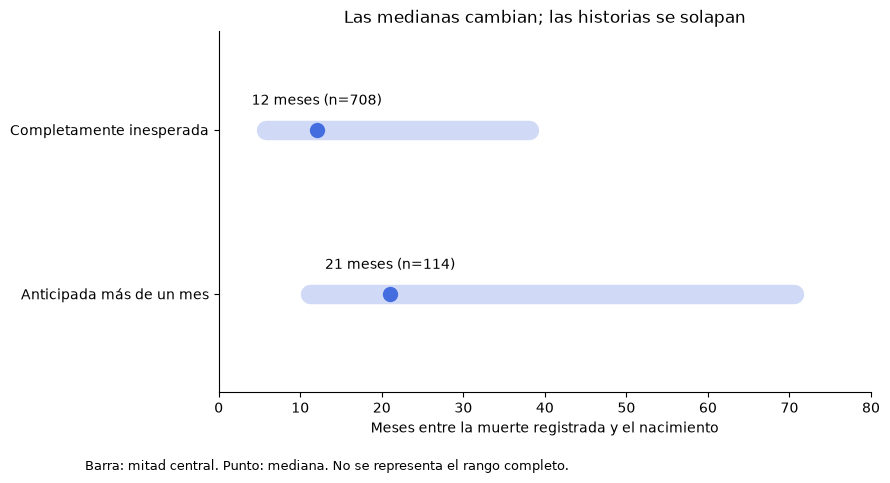

In [2]:
# resumo todos los niveles para evitar seleccionar solo los extremos favorables
resumen = comparables.groupby('death_unexp').intermp.agg(n='size', mediana='median', media='mean', minimo='min', maximo='max')
resumen['p25'] = comparables.groupby('death_unexp').intermp.quantile(.25)
resumen['p75'] = comparables.groupby('death_unexp').intermp.quantile(.75)
display(resumen)
esperados = comparables.loc[comparables.death_unexp.eq(0), 'intermp']
inesperados = comparables.loc[comparables.death_unexp.eq(4), 'intermp']
reduccion = 100 * (1 - inesperados.median() / esperados.median())
print(f'Diferencia de medianas: {esperados.median() - inesperados.median():.0f} meses; reducción relativa: {reduccion:.2f}%')

# represento la mitad central y la mediana con la misma escala
fig, ax = plt.subplots()
for posicion, nivel in enumerate([0, 4]):
    fila = resumen.loc[nivel]
    ax.plot([fila.p25, fila.p75], [posicion, posicion], lw=14, color=color, alpha=.25, solid_capstyle='round')
    ax.scatter(fila.mediana, posicion, color=color, s=100, zorder=3)
    ax.annotate(f'{fila.mediana:.0f} meses (n={fila.n:.0f})', (fila.mediana, posicion), xytext=(0, 18), textcoords='offset points', ha='center')
ax.set_yticks([0, 1], ['Anticipada más de un mes', 'Completamente inesperada'])
ax.set_ylim(-.6, 1.6)
ax.set_xlim(0, 80)
ax.set_xlabel('Meses entre la muerte registrada y el nacimiento')
ax.set_title('Las medianas cambian; las historias se solapan')
fig.text(.1, .01, 'Barra: mitad central. Punto: mediana. No se representa el rango completo.', fontsize=9)
fig.tight_layout(rect=[0,.05,1,1])
plt.show()


Reproduzco 21 y 12 meses: nueve meses de diferencia, un 42,9% respecto al primer grupo. Pero la mitad central va de 11,25 a 70,5 meses en las muertes anticipadas y de 5,75 a 38 en las inesperadas. Hay un solapamiento amplio. Los tamaños también difieren: 114 frente a 708 casos. No interpreto el porcentaje como probabilidad de reencarnación ni como regla para una persona.

## 3. Cuántos registros sostienen la comparación
Cuantifico los filtros para que el tamaño del archivo no se confunda con el tamaño del análisis. No describo como descartes arbitrarios los datos que faltan.

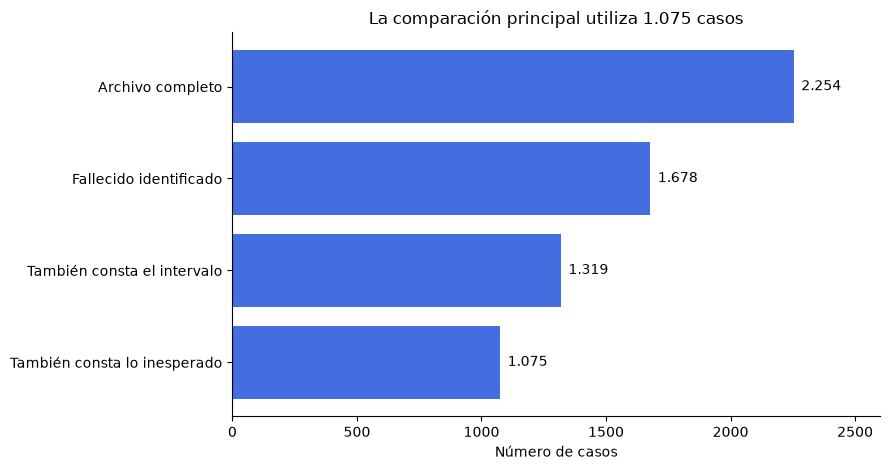

Identificados sin ambas variables: 603 (35.9%)


In [3]:
# cuento cada etapa sin atribuir motivos a las ausencias
etapas = pd.Series([len(datos), len(identificados), int(identificados.intermp.count()), len(comparables)], index=['Archivo completo', 'Fallecido identificado', 'También consta el intervalo', 'También consta lo inesperado'])
fig, ax = plt.subplots()
ax.barh(etapas.index, etapas.values, color=color)
ax.invert_yaxis()
ax.set_xlim(0, 2600)
for i, valor in enumerate(etapas):
    ax.text(valor + 30, i, f'{valor:,}'.replace(',', '.'), va='center')
ax.set_xlabel('Número de casos')
ax.set_title('La comparación principal utiliza 1.075 casos')
fig.tight_layout()
plt.show()
print(f'Identificados sin ambas variables: {len(identificados)-len(comparables)} ({100*(1-len(comparables)/len(identificados)):.1f}%)')


El 35,9% de los casos con fallecido identificado no entra en esta comparación. Esto no invalida automáticamente la asociación, pero limita a quién describe y obliga a evitar expresiones como «los 1.678 casos muestran…» cuando calculo una relación con 1.075.

## 4. Comprobaciones de estabilidad
Reproduzco la correlación con el intervalo transformado que emplean los autores: sumo cuatro meses para admitir el mínimo negativo y aplico el logaritmo, que comprime las distancias más largas. No interpreto su cuadrado como porcentaje de meses explicados. También comparo rangos, excluyo intervalos negativos y restrinjo a documentación precisa. Son comprobaciones descriptivas, no modelos de predicción.

La documentación precisa se refiere a fecha y modo de muerte; tampoco verifica vidas anteriores. Las comparaciones pequeñas pueden variar mucho y no demostrarían diferencias entre grupos sin un análisis adicional.

In [4]:
# compruebo la asociación bajo filtros explícitos y conservo todos los resultados
filas = []
for nombre, grupo in [('Principal', comparables), ('Sin intervalos negativos', comparables.loc[comparables.intermp.ge(0)]), ('Documentación precisa', comparables.loc[comparables.stringent_verif.eq(True)]), ('Sin conexión familiar registrada', comparables.loc[comparables.family_assoc.eq(0)])]:
    r = grupo.death_unexp.corr(grupo.intervalo_log)
    rho = grupo.death_unexp.rank().corr(grupo.intermp.rank())
    filas.append({'seleccion': nombre, 'n': len(grupo), 'correlacion_log': r, 'correlacion_rangos': rho})
comprobaciones = pd.DataFrame(filas)
display(comprobaciones)
print('Intervalos negativos en casos identificados:', int(identificados.intermp.lt(0).sum()))
print('Rango completo con intervalo:', identificados.intermp.min(), identificados.intermp.max())


,seleccion,n,correlacion_log,correlacion_rangos
0,Principal,1075,-0.125582,-0.133270
1,Sin intervalos negativos,1074,-0.124429,-0.132357
2,Documentación precisa,743,-0.150384,-0.157042
3,Sin conexión familiar registrada,272,-0.170172,-0.152862


Intervalos negativos en casos identificados: 1
Rango completo con intervalo: -3.0 1800.0


## 5. Límites y conclusión
Distingo el resultado original (asociación entre grado de muerte inesperada e intervalo) de mi aportación: muestro juntos el tamaño efectivo de la muestra y el solapamiento que ocultan las dos medianas.

No dispongo de una muestra aleatoria de niños ni de un grupo de comparación de la población. No puedo comprobar relatos, fechas, independencia de los casos o contactos informales entre familias con este CSV. Tampoco puedo ajustar por países, épocas o investigadores. Las comprobaciones disponibles no eliminan todos los sesgos de selección e información.

Encuentro una diferencia entre los grupos, pero no una separación clara de sus historias. La asociación descriptiva no identifica su causa. No puedo convertirla en prueba de reencarnación, ni usar este análisis para demostrar lo contrario. Mi conclusión es más concreta: nueve meses entre medianas no resumen por sí solos la dispersión ni las ausencias del archivo.

## 6. Exportación reproducible
Guardo los resúmenes usados por el artículo y las versiones del entorno. Para repetir el EDA basta con instalar `requirements.txt`, abrir este cuaderno en su carpeta y ejecutar todas las celdas. No necesita conexión a internet.

In [5]:
# exporto cifras comprobadas para que el artículo no dependa de transcripciones manuales
resumen.to_csv(ruta / 'resumen_grados.csv')
comprobaciones.to_csv(ruta / 'comprobaciones.csv', index=False)
resultado = {'archivo': len(datos), 'identificados': len(identificados), 'con_intervalo': int(identificados.intermp.count()), 'comparables': len(comparables), 'reduccion_mediana_pct': reduccion, 'grados': resumen.reset_index().to_dict('records'), 'comprobaciones': filas}
(ruta / 'resultados.json').write_text(json.dumps(resultado, ensure_ascii=False, indent=2), encoding='utf-8')
import platform
print({'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__})


{'python': '3.12.14', 'pandas': '3.0.1', 'numpy': '2.5.4'}
